In [32]:
import cvxeda
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [43]:
wesad_data = pd.read_csv("../Data/wesad_eda/filtered_eda_signals.csv")
wesad_data.iloc[0:6,0]

0    0.000000
1    0.024334
2    0.070629
3    0.112352
4    0.122235
5    0.105948
Name: S15_EDA, dtype: float64

In [35]:
r, p, t, l, d, e, obj = cvxeda.cvxEDA(wesad_data.iloc[:, 0], 1.0 / 4, options={"show_progress": False}
)


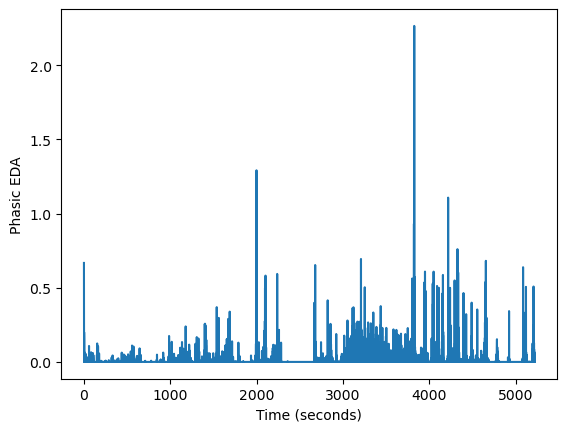

In [36]:
time = np.arange(len(p)) / 4

plt.plot(time, p, label='phasic component')
plt.xlabel('Time (seconds)')
plt.ylabel('Phasic EDA')
plt.show()

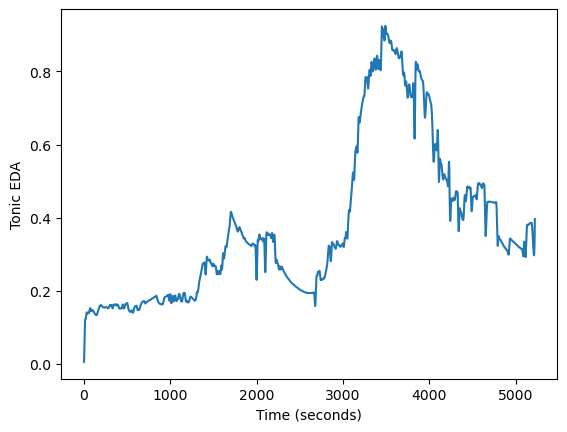

In [37]:
time = np.arange(len(t)) / 4

plt.plot(time, t)
plt.xlabel('Time (seconds)')
plt.ylabel('Tonic EDA')
plt.show()

Grab a dictionary of every participant ID then follow the dataframe label logic to extract directly their EDA column and Label column then apply the CVXeda decomposition and store their tonic and phasic components in new dataframes with their respective participant ID.

In [38]:
tonic_signals = []
phasic_signals = []

# Dictionary of participant IDs
subject_ids = list(dict.fromkeys([col.split('_')[0] for col in wesad_data.columns]))

for subject_id in subject_ids:
    eda_col = f'{subject_id}_EDA'
    label_col = f'{subject_id}_Label'

    eda_signal = wesad_data[eda_col]
    labels = wesad_data[label_col]

    # Apply cvxEDA decomposition
    r, p, t, l, d, e, obj = cvxeda.cvxEDA(eda_signal, 1.0 / 4, options={"show_progress": False})
        
    # Build the structured DataFrame for the current participant
    tonic_dataframe = pd.DataFrame({
            f'{subject_id}_Tonic': t,
            f'{subject_id}_Label': labels
        })

    phasic_dataframe = pd.DataFrame({
                    f'{subject_id}_Phasic': p,
                    f'{subject_id}_Label': labels
                })
        
    tonic_signals.append(tonic_dataframe)
    phasic_signals.append(phasic_dataframe)
    

        


# Combine all subject results
#final_filtered_data = pd.concat(filtered_signals, axis=1)

In [39]:
tonic_csv = pd.concat(tonic_signals, axis=1)
tonic_csv.head()

,S15_Tonic,S15_Label,S7_Tonic,S7_Label,S3_Tonic,S3_Label,S2_Tonic,S2_Label,S14_Tonic,S14_Label,...,S4_Tonic,S4_Label,S13_Tonic,S13_Label,S5_Tonic,S5_Label,S9_Tonic,S9_Label,S6_Tonic,S6_Label
0,0.005656,0.0,-0.068041,0.0,-0.000430,0.0,-0.106189,0.0,-0.028230,0.0,...,-0.000392,0.0,-0.060439,0.0,0.002262,0.0,0.004407,0.0,-0.011996,0
1,0.005722,0.0,-0.064658,0.0,0.000458,0.0,-0.104696,0.0,-0.030292,0.0,...,0.002046,0.0,-0.054811,0.0,0.000612,0.0,0.004703,0.0,-0.011509,0
2,0.006034,0.0,-0.060006,0.0,0.001957,0.0,-0.102362,0.0,-0.031942,0.0,...,0.004640,0.0,-0.048224,0.0,-0.000887,0.0,0.005483,0.0,-0.010431,0
3,0.006580,0.0,-0.054140,0.0,0.004041,0.0,-0.099216,0.0,-0.033191,0.0,...,0.007387,0.0,-0.040719,0.0,-0.002237,0.0,0.006727,0.0,-0.008786,0
4,0.007352,0.0,-0.047109,0.0,0.006685,0.0,-0.095285,0.0,-0.034050,0.0,...,0.010279,0.0,-0.032341,0.0,-0.003436,0.0,0.008417,0.0,-0.006598,0


In [40]:
phasic_csv = pd.concat(phasic_signals, axis=1)
phasic_csv.head()

,S15_Phasic,S15_Label,S7_Phasic,S7_Label,S3_Phasic,S3_Label,S2_Phasic,S2_Label,S14_Phasic,S14_Label,...,S4_Phasic,S4_Label,S13_Phasic,S13_Label,S5_Phasic,S5_Label,S9_Phasic,S9_Label,S6_Phasic,S6_Label
0,6.674665e-01,0.0,5.005772e+00,0.0,9.239485e-01,0.0,7.014715e+00,0.0,2.777665e+00,0.0,...,3.368906e-01,0.0,4.482422e+00,0.0,7.153653e-01,0.0,7.319026e-01,0.0,1.702026e+00,0
1,3.965376e-01,0.0,3.970642e+00,0.0,2.412977e+00,0.0,7.151264e-01,0.0,2.162970e-07,0.0,...,7.313398e-02,0.0,2.077439e+00,0.0,3.669041e-01,0.0,1.265518e+00,0.0,1.477522e+00,0
2,7.135253e-08,0.0,5.977528e-08,0.0,1.897672e-08,0.0,5.691367e-09,0.0,2.055804e-08,0.0,...,1.935313e-08,0.0,3.048868e-08,0.0,9.861152e-08,0.0,5.868422e-08,0.0,5.454043e-08,0
3,3.010073e-08,0.0,2.071860e-08,0.0,6.877174e-09,0.0,1.969692e-09,0.0,8.874459e-09,0.0,...,7.533493e-09,0.0,1.088312e-08,0.0,3.908426e-08,0.0,2.306767e-08,0.0,2.043192e-08,0
4,2.394813e-08,0.0,1.475005e-08,0.0,4.751437e-09,0.0,1.407342e-09,0.0,7.256875e-09,0.0,...,5.457764e-09,0.0,7.915624e-09,0.0,2.863984e-08,0.0,1.699469e-08,0.0,1.489959e-08,0


In [41]:
tonic_csv.to_csv("../Data/wesad_eda/tonic_signal.csv", index=False)
phasic_csv.to_csv("../Data/wesad_eda/phasic_signal.csv", index=False)
